# [TOPIC 20] cGAN 구현하기

지난 시간에 GAN 의 원리를 살펴봤어요. 두 신경망을 경쟁시켜 진짜 같은 이미지를 만들어 냈지만, 한 가지 아쉬움이 있었죠. 무엇을 만들지는 고를 수 없었다는 점이에요. 이번에는 거기에 **조건**을 더한 cGAN 을 코드로 직접 만들어 봅니다. 0 부터 9 까지 손글씨 숫자로 이뤄진 MNIST 로 학습시키고, 원하는 숫자를 지정해 생성하는 것까지 해볼 거예요.

---

## 1. cGAN 으로 무엇이 달라지나

지난 시간의 GAN 은 무작위 잡음에서 진짜 같은 이미지를 만들어 냈지만, 무엇을 만들지는 고를 수 없었어요. 잡음을 넣으면 숫자가 나오긴 하는데 그게 3 일지 7 일지는 통제할 수 없었죠. 우리가 원하는 건 "이 종류의 이미지를 만들어 줘" 라고 지정하는 거예요. 이걸 가능하게 하는 것이 cGAN(Conditional GAN), 곧 조건을 붙인 GAN 입니다.

핵심 아이디어는 단순해요. 두 신경망 모두에 **조건(라벨) $y$ 를 입력으로 추가**하는 것뿐이에요.

생성자는 이제 잡음 $z$ 와 라벨 $y$ 를 함께 받습니다. "이 잡음으로, 그런데 $y$ 종류의 이미지를 만들어라" 라는 주문인 셈이죠. 같은 잡음이라도 $y$ 가 바뀌면 다른 종류의 이미지가 나오도록 학습돼요.

판별자도 이미지와 라벨 $y$ 를 함께 받습니다. 그리고 단순히 "이게 진짜인가" 가 아니라 **"이게 진짜이면서 $y$ 종류에 맞는가"** 를 판단해요. 이 점이 중요합니다. 만약 판별자가 진짜다움만 본다면, 생성자는 라벨과 상관없이 진짜 같은 이미지 하나만 잘 만들어도 판별자를 속일 수 있어요. 7 을 요청했는데 그럴듯한 3 을 내놓아도 통과해 버리는 거죠. 판별자에게 라벨을 같이 주면, 진짜처럼 보이더라도 라벨과 어긋난 이미지는 가짜로 걸러집니다. 그래서 생성자는 라벨에 맞는 이미지를 만들 수밖에 없어요. **조건을 판별자에도 넣는 것**이 생성 결과를 원하는 종류에 묶어 두는 장치인 셈입니다.

손실은 지난 시간의 GAN 과 똑같아요. 식의 모양은 그대로고, $D$ 와 $G$ 의 입력에 $y$ 가 더해질 뿐이죠.



$$
Loss_D = -\left[\log D(x \mid y) + \log\left(1 - D(G(z \mid y) \mid y)\right)\right]
$$

$$
\qquad Loss_G = -\log D(G(z \mid y) \mid y)
$$


학습 방식도 그대로입니다. 판별자와 생성자를 번갈아 갱신하고, 평형에 이르면 판별자를 떼어 내요. 달라지는 건 생성할 때예요. 학습이 끝나면 잡음과 함께 **원하는 라벨**을 생성자에 넣어, 그 종류의 이미지를 골라서 만들 수 있습니다. 이번 시연에서는 0 부터 9 까지 손글씨 숫자로 이뤄진 MNIST 로 cGAN 을 학습시키고, 원하는 숫자를 지정해 생성해 봅니다.

## 2. 환경 설정

In [ ]:
# 한글 폰트 설치
!sudo apt-get -qq install -y fonts-nanum > /dev/null

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# 한글 폰트 적용
fm.fontManager.addfont("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
print(f"사용 장치: {device}")

debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 78, <> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
사용 장치: cuda


## 3. 데이터 — MNIST

MNIST 는 0 부터 9 까지 손으로 쓴 숫자를 모은 28×28 흑백 이미지 데이터예요. 생성 모델을 처음 익히기에 가장 많이 쓰이는 데이터죠. cGAN 에서는 이미지뿐 아니라 각 이미지의 숫자(라벨)도 함께 쓰니, 라벨까지 같이 불러옵니다.

torchvision 에 들어 있어 한 줄로 바로 내려받을 수 있어요. 픽셀값은 생성자의 마지막 활성화 함수인 Tanh 의 출력 범위에 맞춰 −1 에서 1 사이로 정규화합니다.

In [ ]:
# MNIST: 0~9 손글씨 숫자, 28x28 흑백 10종
class_names = [str(digit) for digit in range(10)]
num_classes = 10

# ToTensor 로 0~1, Normalize 로 -1~1 (생성자의 Tanh 출력 범위에 맞춤)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

batch_size = 128
train_set = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, drop_last=True)
print(f"전체 이미지 수: {len(train_set)}")

100%|██████████| 9.91M/9.91M [00:01<00:00, 4.98MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 130kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.1MB/s]

전체 이미지 수: 60000


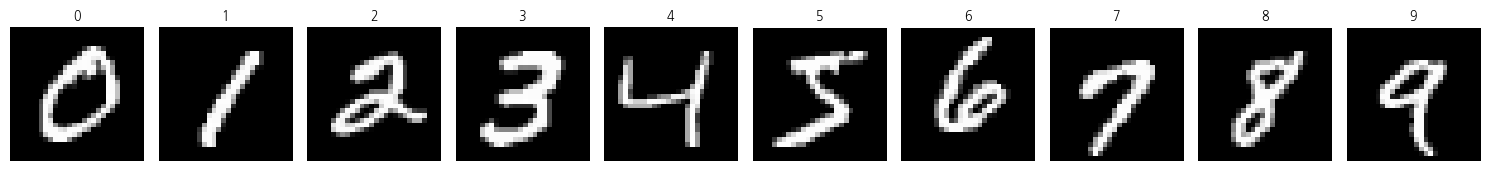

In [ ]:
# 데이터 살펴보기 — 숫자별로 한 장씩
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for label in range(10):
    idx = (train_set.targets == label).nonzero()[0].item()
    axes[label].imshow(train_set.data[idx], cmap="gray")
    axes[label].set_title(class_names[label], fontsize=9)
    axes[label].axis("off")
plt.tight_layout()
plt.show()

## 4. 생성자 — 조건을 받는 Generator

생성자는 잡음 $z$ 와 라벨을 함께 받아, 그 종류의 이미지를 만듭니다. 라벨은 숫자 하나일 뿐이라 그대로 쓰기 어려우니, **임베딩(Embedding)** 으로 길이 10 의 벡터로 바꿔 잡음에 이어 붙여요. 그렇게 합친 벡터를 작은 특징 맵으로 펼친 뒤, ConvTranspose 로 크기를 키워 28×28 이미지를 만들죠.

In [ ]:
latent_dim = 100   # 잡음 z 의 차원
embed_dim = 10     # 라벨을 펼칠 임베딩 차원


class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        # 라벨을 embed_dim 차원 벡터로 바꾸는 임베딩
        self.label_emb = nn.Embedding(num_classes, embed_dim)
        # 잡음 + 라벨 벡터를 7x7 특징 맵으로 펼치기
        self.fc = nn.Linear(latent_dim + embed_dim, 128 * 7 * 7)
        self.net = nn.Sequential(
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1),  # 7 -> 14
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, 4, 2, 1),    # 14 -> 28
            nn.Tanh(),
        )

    def forward(self, z, labels):
        # 잡음과 라벨 임베딩을 이어 붙임
        x = torch.cat([z, self.label_emb(labels)], dim=1)
        x = self.fc(x).view(-1, 128, 7, 7)
        return self.net(x)

### 코드 뜯어보기

- `nn.Embedding(num_classes, embed_dim)` — 0 부터 9 까지의 라벨 하나하나에 학습 가능한 길이 10 벡터를 배정합니다. 라벨이라는 정수를 신경망이 다루기 좋은 벡터로 바꿔 주는 표예요.
- `torch.cat([z, ...], dim=1)` — 잡음 벡터와 라벨 벡터를 하나로 잇습니다. 이렇게 합쳐 넣기에 같은 잡음이라도 라벨이 바뀌면 다른 종류가 나와요.
- `ConvTranspose2d(..., 4, 2, 1)` — 특징 맵의 가로세로를 두 배로 키우는 층입니다. 7×7 에서 시작해 14×14, 28×28 로 키워 이미지 크기를 맞춰요.
- 마지막 `Tanh` — 출력을 −1 에서 1 사이로 내보내, 같은 범위로 정규화한 진짜 이미지와 맞춰요.

## 5. 판별자 — 조건을 받는 Discriminator

판별자는 이미지와 라벨을 함께 받아, **진짜이면서 그 라벨에 맞는지**를 0 과 1 사이 확률로 답합니다. 라벨을 이미지와 같은 크기(28×28)의 맵으로 펼쳐 이미지에 한 채널로 덧붙인 뒤, Conv 로 특징을 뽑아 마지막에 하나의 확률을 내요. 라벨을 이렇게 같이 넣어야, 진짜처럼 보여도 라벨과 어긋난 이미지를 가짜로 가려낼 수 있어요.

In [ ]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        # 라벨을 28x28 크기로 펼쳐 이미지에 덧붙이기 위한 임베딩
        self.label_emb = nn.Embedding(num_classes, 28 * 28)
        self.net = nn.Sequential(
            nn.Conv2d(2, 64, 4, 2, 1),
            nn.LeakyReLU(0.2, True),

            nn.Conv2d(64, 128, 4, 2, 1),
            nn.LeakyReLU(0.2, True),

            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1),
        )

    def forward(self, img, labels):
        # 라벨을 28x28 맵으로 펼쳐 이미지와 채널 방향으로 합침
        label_map = self.label_emb(labels).view(-1, 1, 28, 28)
        x = torch.cat([img, label_map], dim=1)
        return self.net(x)

### 코드 뜯어보기

- `nn.Embedding(num_classes, 28 * 28)` — 라벨을 784 개 값으로 바꾼 뒤 28×28 맵으로 펼칩니다. 이미지와 같은 모양이라 한 채널로 덧붙일 수 있어요.
- `Conv2d(2, 64, ...)` — 첫 입력 채널이 2 인 이유는 이미지(1채널)에 라벨 맵(1채널)을 더했기 때문이에요. 판별자가 이미지와 라벨을 함께 보도록 만드는 부분입니다.

아래는 두 신경망이 의도한 모양으로 동작하는지 확인하는 Sanity Check 예요. 잡음과 라벨을 넣어 생성자가 28×28 이미지를 내놓는지, 판별자가 0~1 확률 하나를 내놓는지 점검해요.

In [ ]:
generator = Generator().to(device)
discriminator = Discriminator().to(device)

# Sanity Check — 차원과 출력 범위
z = torch.randn(8, latent_dim, device=device)
labels = torch.randint(0, num_classes, (8,), device=device)
fake = generator(z, labels)
score = discriminator(fake, labels)

print(f"생성자 출력: {tuple(fake.shape)}")
print(f"판별자 출력: {tuple(score.shape)}")
print(f"판별자 점수 범위: {score.min().item():.3f} ~ {score.max().item():.3f}")
print(f"생성자 파라미터 수: {sum(p.numel() for p in generator.parameters())}")
print(f"판별자 파라미터 수: {sum(p.numel() for p in discriminator.parameters())}")

생성자 출력: (8, 1, 28, 28)
판별자 출력: (8, 1)
판별자 점수 범위: -0.062 ~ 0.085
생성자 파라미터 수: 828837
판별자 파라미터 수: 147425


## 6. 손실과 학습 루프

손실은 지난 시간에 본 이진 교차 엔트로피(BCEWithLogitsLoss)예요. 판별자는 진짜를 1, 가짜를 0 으로 맞히도록, 생성자는 자기 가짜가 1 로 분류되도록 학습하죠. 두 신경망은 각자의 옵티마이저로 따로 갱신해요. 한 스텝에서는 판별자를 먼저, 생성자를 나중에 갱신해요.

In [ ]:
criterion = nn.BCEWithLogitsLoss()
# 판별자가 너무 빨리 강해지지 않도록 학습률을 생성자보다 낮게 둡니다.
optimizer_G = torch.optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=0.0001, betas=(0.5, 0.999))

g_steps = 2  # 생성자 갱신 횟수. 생성자가 판별자에 밀리면 2 이상으로 올려 더 자주 학습시킬 수 있어요


def train_one_epoch():
    """한 에폭 동안 판별자와 생성자를 번갈아 학습시킵니다.

    판별자를 한 번 갱신할 때 생성자는 g_steps 번 갱신해, 더 쉬운 일을 맡은
    판별자가 너무 앞서가지 않도록 균형을 맞춥니다.

    Returns:
        (판별자 평균 손실, 생성자 평균 손실) 튜플.
    """
    generator.train()
    discriminator.train()
    d_running, g_running = 0.0, 0.0
    for real, labels in train_loader:
        real, labels = real.to(device), labels.to(device)
        n_samples = real.size(0)
        real_smooth = torch.full((n_samples, 1), 0.9, device=device)  # 라벨 스무딩 (1 대신 0.9)
        fake_target = torch.zeros(n_samples, 1, device=device)
        real_target = torch.ones(n_samples, 1, device=device)

        # --- 판별자 학습 (생성자는 고정) ---
        z = torch.randn(n_samples, latent_dim, device=device)
        fake = generator(z, labels)
        loss_real = criterion(discriminator(real, labels), real_smooth)
        loss_fake = criterion(discriminator(fake.detach(), labels), fake_target)  # detach() 로 그라디언트 끊기
        loss_D = loss_real + loss_fake
        optimizer_D.zero_grad()
        loss_D.backward()
        optimizer_D.step()

        # --- 생성자 학습 (g_steps 만큼 반복) ---
        for _ in range(g_steps):
            z = torch.randn(n_samples, latent_dim, device=device)
            fake = generator(z, labels)
            loss_G = criterion(discriminator(fake, labels), real_target)  # 가짜를 진짜(1)로 분류시키기
            optimizer_G.zero_grad()
            loss_G.backward()
            optimizer_G.step()

        d_running += loss_D.item()
        g_running += loss_G.item()
    return d_running / len(train_loader), g_running / len(train_loader)

### 코드 뜯어보기

- 옵티마이저가 두 개인 이유 — 판별자와 생성자는 목표가 반대라 따로 갱신해야 합니다. `optimizer_D` 는 판별자 가중치만, `optimizer_G` 는 생성자 가중치만 움직여요.
- `fake.detach()` — 판별자를 학습할 때는 생성자로 기울기가 흘러가면 안 됩니다. `detach` 로 끊어, 이 단계에서는 판별자만 갱신되도록 해요.
- 생성자 단계의 목표값이 `real_target`(1) 인 점 — 생성자는 자기 가짜가 진짜로 분류되길 원하므로, 가짜에 1 라벨을 주고 손실을 줄입니다. 곧 판별자를 속이는 방향이에요.
- 두 단계 모두 라벨을 그대로 넘겨, 생성도 판별도 같은 종류를 기준으로 이뤄지도록 합니다.
- 진짜 라벨을 1 대신 **0.9** 로 두는 라벨 스무딩 — 판별자가 과신해 생성자에게 가는 신호를 죽이는 걸 막아요.
- 판별자 학습률을 생성자보다 **낮게**(판별자 1e-4, 생성자 2e-4) — 판별자가 너무 빨리 강해져 균형이 무너지는 걸 늦춰요.
- 생성자 갱신 횟수(`g_steps`) — 판별자가 너무 앞서갈 때 생성자를 한 스텝에 여러 번 갱신해 따라잡게 하는 기법이에요. 여기서는 1 로 두지만, 생성자가 밀리면 2 이상으로 올릴 수 있어요.

## 7. 학습 실행

이제 학습을 돌립니다. 에폭마다 두 손실을 출력해, 판별자와 생성자가 서로 밀고 당기는 흐름을 지켜볼 수 있어요.

In [ ]:
n_epochs = 20
d_hist, g_hist = [], []
for epoch in range(1, n_epochs + 1):
    loss_D, loss_G = train_one_epoch()
    d_hist.append(loss_D)
    g_hist.append(loss_G)
    if epoch % 5 == 0 or epoch == 1:
        print(f"에폭 {epoch:2d} | loss_D {loss_D:.3f} | loss_G {loss_G:.3f}")

에폭  1 | loss_D 1.259 | loss_G 1.022
에폭  5 | loss_D 1.350 | loss_G 0.824
에폭 10 | loss_D 1.379 | loss_G 0.803
에폭 15 | loss_D 1.379 | loss_G 0.801
에폭 20 | loss_D 1.379 | loss_G 0.800


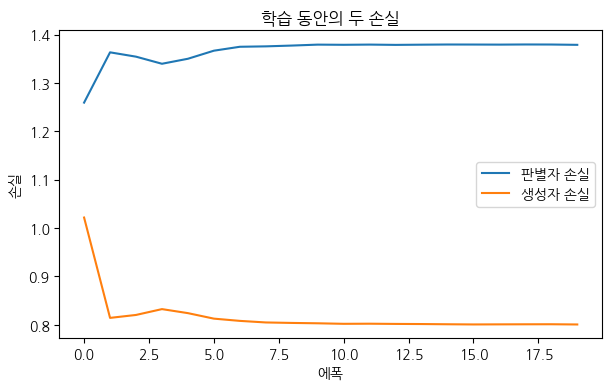

In [ ]:
# 손실 곡선
plt.figure(figsize=(7, 4))
plt.plot(d_hist, label="판별자 손실")
plt.plot(g_hist, label="생성자 손실")
plt.xlabel("에폭")
plt.ylabel("손실")
plt.legend()
plt.title("학습 동안의 두 손실")
plt.show()

## 8. 조건부 생성 — 원하는 종류 만들기

학습이 끝난 생성자에 **원하는 라벨**을 넣어, 그 종류만 골라 생성해 봅니다. 행마다 종류를 하나씩 고정하고, 열을 따라 다른 잡음을 넣었어요. 같은 종류 안에서도 잡음이 바뀌면 조금씩 다른 모양이 나오는 걸 볼 수 있습니다. GAN 의 무작위 생성과 달리, 이제는 어떤 종류를 만들지 우리가 정할 수 있어요.

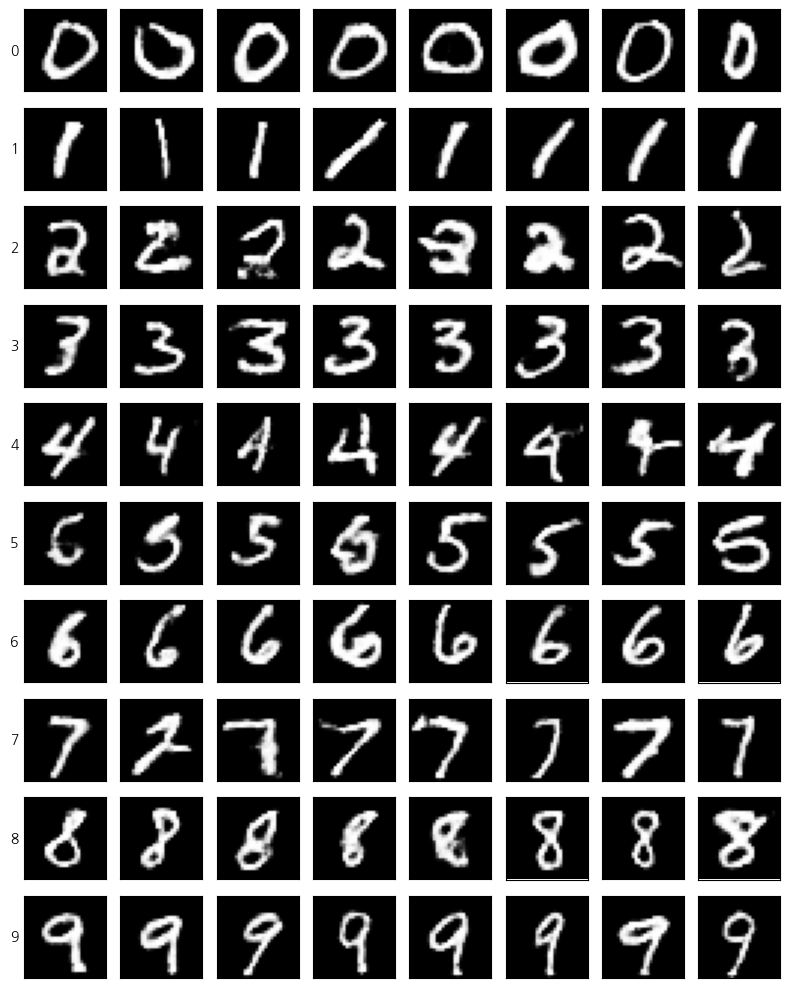

In [ ]:
generator.eval()
n_per_class = 8  # 종류마다 생성할 개수

with torch.no_grad():
    fig, axes = plt.subplots(10, n_per_class, figsize=(n_per_class, 10))
    for label in range(10):
        z = torch.randn(n_per_class, latent_dim, device=device)
        y = torch.full((n_per_class,), label, device=device)
        gen = generator(z, y).cpu()
        gen = (gen + 1) / 2  # -1~1 을 0~1 로 되돌리기
        for j in range(n_per_class):
            ax = axes[label][j]
            ax.imshow(gen[j].squeeze(), cmap="gray")
            ax.set_xticks([])
            ax.set_yticks([])
        axes[label][0].set_ylabel(class_names[label], rotation=0,
                                  ha="right", va="center", fontsize=10)
    plt.tight_layout()
    plt.show()

In [ ]:
# 한 종류만 골라 여러 장 생성하기 — 예: 숫자 7(라벨 7)
target_label = 7
generator.eval()
with torch.no_grad():
    z = torch.randn(16, latent_dim, device=device)
    y = torch.full((16,), target_label, device=device)
    gen = (generator(z, y).cpu() + 1) / 2   # -1 ~ 1 을 0 ~ 1 로 되돌리기

fig, axes = plt.subplots(2, 8, figsize=(8, 2.5))
for ax, img in zip(axes.flat, gen):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.axis("off")
fig.suptitle(f"“{class_names[target_label]}” 만 골라 생성한 결과")
plt.tight_layout()
plt.show()

## 9. 생성 품질 평가

학습이 끝난 모델이 얼마나 잘 만드는지 가늠해 볼게요. loss_D 와 loss_G 는 두 신경망이 경쟁하며 밀고 당기는 값이라, 낮다고 좋은 것도 아니고 둘의 격차가 품질을 알려주지도 않아요. 손실은 학습이 안정적인지, 즉 한쪽이 0 으로 붕괴하거나 끝없이 치솟지 않는지를 보는 용도에 가깝습니다.

그래서 평가는 두 갈래로 나눠요. 눈으로 보는 **정성 평가**와 FID 와 IS 를 활용한 **정량 평가**입니다.

- **FID(Fréchet Inception Distance)**

    **FID(Fréchet Inception Distance)** 는 진짜 이미지와 생성 이미지를 각각 Inception 신경망에 통과시켜 얻은 특징의 분포를 비교해, 둘이 얼마나 가까운지를 잽니다. **낮을수록** 진짜에 가까워요. 진짜 데이터와 직접 견주는 방식이라 가장 널리 쓰이는 지표예요.

- **IS(Inception Score)**

    **IS(Inception Score)** 는 생성 이미지을 하나씩 Inception(ImageNet 분류기)에 넣어 계산된 확률 분포를 활용해서 평가합니다. 두 가지 측면으로 평가를 진행해요.

    하나는 그림 한 장의 분포가 한 종류에 **뾰족하게** 쏠리는지예요. 확신 정도(Confidence) 가 높은지 보는 겁니다. 분류기가 “이건 확실히 OO” 라고 자신 있게 답한다는 건 그만큼 또렷하게 잘 그려졌다는 신호죠.

    다른 하나는 생성한 그림 전체의 분포를 평균 냈을 때 여러 종류로 **넓게** 퍼지는지예요. 매번 같은 것만 찍어내지 않고 다양하게 만든다는 뜻이거든요.

    그렇기 때문에 IS 는 각 이미지에 대한 확신 정도가 높을 수록, 전체적으로 봤을 때는 분포가 넓을 수록 점수가 높아집니다. 다만 이 모든 게 Inception 의 ImageNet 클래스 판단에 기대고 진짜 데이터와는 비교하지 않아서, 우리처럼 자연 이미지가 아닌 데이터에서는 의미가 약합니다.

사실 두 지표 모두 자연 이미지로 학습된 Inception 을 쓰는데 우리 데이터는 28×28 흑백 숫자라 딱 들어맞진 않아요. 특히 IS 는 숫자를 ImageNet 클래스로 해석하는 셈이라 의미가 약하고, FID 는 분포 거리라 상대 비교용으로는 쓸 만해요. 그래서 여기서는 FID 를 재 보고, IS 는 개념만 알아 둡니다.

In [ ]:
import torch.nn.functional as F
import scipy.linalg
from torchvision.models import inception_v3, Inception_V3_Weights


# 사전 학습된 Inception 에서 마지막 분류층을 떼어, 2048차원 특징 추출기로 씁니다.
inception = inception_v3(weights=Inception_V3_Weights.IMAGENET1K_V1, transform_input=False)
inception.fc = nn.Identity()
inception.eval().to(device)

imagenet_mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
imagenet_std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)


def inception_features(batch):
    """[-1, 1] 흑백 이미지를 Inception 입력 규격으로 맞춰 2048차원 특징을 뽑습니다."""
    x = (batch + 1) / 2                  # 0 ~ 1
    x = x.repeat(1, 3, 1, 1)             # 1채널 -> 3채널
    x = F.interpolate(x, size=(299, 299), mode="bilinear", align_corners=False)
    x = (x - imagenet_mean) / imagenet_std
    with torch.no_grad():
        return inception(x).cpu().numpy()


def fid_score(real_features, fake_features):
    """두 특징 집합의 평균과 공분산으로 Fréchet 거리를 계산합니다."""
    mu_real, mu_fake = real_features.mean(0), fake_features.mean(0)
    cov_real = np.cov(real_features, rowvar=False)
    cov_fake = np.cov(fake_features, rowvar=False)
    cov_mean = scipy.linalg.sqrtm(cov_real @ cov_fake)
    if np.iscomplexobj(cov_mean):
        cov_mean = cov_mean.real
    diff = mu_real - mu_fake
    return float(diff @ diff + np.trace(cov_real + cov_fake - 2 * cov_mean))


FID 는 정해진 범위가 없어, 좋다고 판단할 수 있는 **기준점**이 필요합니다. 가장 깔끔한 기준은 진짜 데이터끼리 재 보는 거예요. 진짜 이미지를 겹치지 않는 두 묶음으로 나눠 서로의 FID 를 재면, 같은 분포에서 나온 두 표본 사이의 거리가 나옵니다. 이게 이 설정에서 FID 가 내려갈 수 있는 **바닥값**, 곧 최선의 점수예요.


In [ ]:
# 겹치지 않는 진짜 이미지 2 * n_eval 장 모으기

n_eval = 5000

baseline_images = []
collected = 0
for real, _ in train_loader:
    baseline_images.append(real)
    collected += real.size(0)
    if collected >= 2 * n_eval:
        break
baseline_images = torch.cat(baseline_images)

# 두 묶음으로 분리 (서로 겹치지 않음)
half = min(n_eval, len(baseline_images) // 2)
group_a = baseline_images[:half]
group_b = baseline_images[half : 2 * half]


def collect_features(images):
    """이미지 묶음을 배치 단위로 나눠 Inception 특징을 모읍니다."""
    feats = []
    for i in range(0, len(images), batch_size):
        feats.append(inception_features(images[i : i + batch_size].to(device)))
    return np.concatenate(feats)


feats_a = collect_features(group_a)
feats_b = collect_features(group_b)
baseline_fid = fid_score(feats_a, feats_b)
print(f"진짜 vs 진짜 기준선 FID: {baseline_fid:.2f}  (각 묶음 {half}장)")

진짜 vs 진짜 기준선 FID: 2.60  (각 묶음 5000장)


같은 진짜 데이터를 둘로 나눈 것뿐인데도 그 값이 0 이 아니라는 점이 흥미롭죠. 아무리 같은 데이터에서 나온 분포라고 해도, 데이터가 유한한 한 미세한 차이는 늘 존재할 수 밖에 없기 때문이에요. 이 바닥값을 계산해두면 생성 FID 가 어느 정도인지 가늠해볼 수 있어요. 이제 이어서 생성된 이미지에 대한 FID 를 계산해봅시다.

In [ ]:
n_eval = 5000
real_feats, fake_feats = [], []

# 진짜 이미지: 학습 데이터에서 n_eval 장의 특징
real_count = 0
for real, _ in train_loader:
    real_feats.append(inception_features(real.to(device)))
    real_count += real.size(0)
    if real_count >= n_eval:
        break

# 생성 이미지: 같은 수만큼
generator.eval()
for i in range(0, real_count, batch_size):
    n = min(batch_size, real_count - i)
    z = torch.randn(n, latent_dim, device=device)
    y = torch.randint(0, num_classes, (n,), device=device)
    fake_feats.append(inception_features(generator(z, y)))

real_feats = np.concatenate(real_feats)
fake_feats = np.concatenate(fake_feats)
print(f"FID: {fid_score(real_feats, fake_feats):.2f}  (낮을수록 진짜 분포에 가까움)")

FID: 15.17  (낮을수록 진짜 분포에 가까움)


---

오늘은 GAN 에 조건을 더한 cGAN 을 직접 만들어 봤어요. 주요 내용을 다시 정리해 보겠습니다.

- **조건 결합** — 생성자에는 잡음과 라벨을 이어 붙이고, 판별자에는 라벨을 이미지에 한 채널로 덧붙임. 판별자에도 라벨을 넣어야 생성이 원하는 종류에 묶임.
- **손실과 학습** — GAN 과 똑같은 이진 교차 엔트로피로, 판별자와 생성자를 번갈아 갱신함.
- **조건부 생성** — 학습이 끝난 생성자에 원하는 라벨을 넣어, 만들 종류를 직접 고를 수 있음.

여기서 익힌 조건 결합과 학습 루프는 데이터만 바꾸면 그대로 쓸 수 있어요. 다음 시간에는 또 다른 생성 모델인 Diffusion 의 큰 그림을 살펴볼 거예요. 다음 시간에 뵙겠습니다.